# BITS WILP – M.Tech (AIML)

## Subject: Machine Learning
## Assignment 2: Manufacturing Defect Classification

**Student Name:** Asmita Pawar  
**BITS Student ID:** 2026AJ05338

**Dataset:** Predicting Manufacturing Defects  
**Task:** Binary classification

### Assignment objective
Implement and compare five classification algorithms on the same dataset. Evaluate each model using Accuracy, AUC, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC), then save the trained models and held-out test data for use in the Streamlit application.

**Models:** Logistic Regression, Decision Tree, K-Nearest Neighbors (KNN), Gaussian Naive Bayes, and Support Vector Machine (SVM).

## 1. Import libraries

The notebook uses pandas and NumPy for data handling, Matplotlib for a simple visualization, and scikit-learn for splitting data, building models, and evaluating predictions. `Path` is used to locate files in a way that works across different computers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import joblib

## 2. Locate and load the dataset

Expected file: `data/manufacturing_defect_dataset.csv`.

This cell checks common project locations, including a `data` folder beside the notebook's parent project folder. If the file cannot be found, set `DATA_PATH` manually to the location of the CSV on this computer. Avoid hard-coding a path from a previous PC.

In [2]:
# Search likely locations first, then search below the current working directory.
candidate_paths = [
    Path.cwd() / "data" / "manufacturing_defect_dataset.csv",
    Path.cwd().parent / "data" / "manufacturing_defect_dataset.csv",
    Path.cwd() / "manufacturing_defect_dataset.csv",
]

DATA_PATH = next((path for path in candidate_paths if path.exists()), None)

if DATA_PATH is None:
    matches = list(Path.cwd().rglob("manufacturing_defect_dataset.csv"))
    if matches:
        DATA_PATH = matches[0]

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Place 'manufacturing_defect_dataset.csv' in the "
        "'data' folder of the project, or update DATA_PATH to the correct CSV path."
    )

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded from: {DATA_PATH.resolve()}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns (including target): {df.shape[1]}")
display(df.head())

Dataset loaded from: C:\Users\Windows\Desktop\manufacturing-defect-classifier-main\data\manufacturing_defect_dataset.csv
Rows: 3,240
Columns (including target): 17


,ProductionVolume,ProductionCost,SupplierQuality,DeliveryDelay,DefectRate,QualityScore,MaintenanceHours,DowntimePercentage,InventoryTurnover,StockoutRate,WorkerProductivity,SafetyIncidents,EnergyConsumption,EnergyEfficiency,AdditiveProcessTime,AdditiveMaterialCost,DefectStatus
0,202,13175.403783,86.648534,1,3.121492,63.463494,9,0.052343,8.630515,0.081322,85.042379,0,2419.616785,0.468947,5.551639,236.439301,1
1,535,19770.046093,86.310664,4,0.819531,83.697818,20,4.908328,9.296598,0.038486,99.657443,7,3915.566713,0.119485,9.080754,353.957631,1
2,960,19060.820997,82.132472,0,4.514504,90.350550,1,2.464923,5.097486,0.002887,92.819264,2,3392.385362,0.496392,6.562827,396.189402,1
3,370,5647.606037,87.335966,5,0.638524,67.628690,8,4.692476,3.577616,0.055331,96.887013,8,4652.400275,0.183125,8.097496,164.135870,1
4,206,7472.222236,81.989893,3,3.867784,82.728334,9,2.746726,6.851709,0.068047,88.315554,7,1581.630332,0.263507,6.406154,365.708964,1


## 3. Explore the Dataset

The dataset is explored before model development to understand its structure and identify potential data-quality issues.

The following checks are performed:

- Review the first five records to understand the dataset.
- Examine column names and data types.
- Check for missing values in each column.
- Identify duplicate records.
- Generate descriptive statistics for numerical features.

These checks help ensure that the dataset is suitable for preprocessing and classification modelling.

In [3]:
# Display the first five records
print("1. First five records:")
display(df.head())

# Display column names
print("\n2. Column names:")
print(df.columns.tolist())

# Display dataset dimensions
print("\n3. Dataset dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Display data types and non-null counts
print("\n4. Dataset information:")
df.info()

# Check missing values
print("\n5. Missing values:")
display(df.isnull().sum())

# Check duplicate records
print("\n6. Duplicate records:")
print("Number of duplicate rows:", df.duplicated().sum())

# Generate descriptive statistics
print("\n7. Descriptive statistics:")
display(df.describe().T)

1. First five records:


,ProductionVolume,ProductionCost,SupplierQuality,DeliveryDelay,DefectRate,QualityScore,MaintenanceHours,DowntimePercentage,InventoryTurnover,StockoutRate,WorkerProductivity,SafetyIncidents,EnergyConsumption,EnergyEfficiency,AdditiveProcessTime,AdditiveMaterialCost,DefectStatus
0,202,13175.403783,86.648534,1,3.121492,63.463494,9,0.052343,8.630515,0.081322,85.042379,0,2419.616785,0.468947,5.551639,236.439301,1
1,535,19770.046093,86.310664,4,0.819531,83.697818,20,4.908328,9.296598,0.038486,99.657443,7,3915.566713,0.119485,9.080754,353.957631,1
2,960,19060.820997,82.132472,0,4.514504,90.350550,1,2.464923,5.097486,0.002887,92.819264,2,3392.385362,0.496392,6.562827,396.189402,1
3,370,5647.606037,87.335966,5,0.638524,67.628690,8,4.692476,3.577616,0.055331,96.887013,8,4652.400275,0.183125,8.097496,164.135870,1
4,206,7472.222236,81.989893,3,3.867784,82.728334,9,2.746726,6.851709,0.068047,88.315554,7,1581.630332,0.263507,6.406154,365.708964,1



2. Column names:
['ProductionVolume', 'ProductionCost', 'SupplierQuality', 'DeliveryDelay', 'DefectRate', 'QualityScore', 'MaintenanceHours', 'DowntimePercentage', 'InventoryTurnover', 'StockoutRate', 'WorkerProductivity', 'SafetyIncidents', 'EnergyConsumption', 'EnergyEfficiency', 'AdditiveProcessTime', 'AdditiveMaterialCost', 'DefectStatus']

3. Dataset dimensions:
Rows: 3240
Columns: 17

4. Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3240 entries, 0 to 3239
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ProductionVolume      3240 non-null   int64  
 1   ProductionCost        3240 non-null   float64
 2   SupplierQuality       3240 non-null   float64
 3   DeliveryDelay         3240 non-null   int64  
 4   DefectRate            3240 non-null   float64
 5   QualityScore          3240 non-null   float64
 6   MaintenanceHours      3240 non-null   int64  
 7   DowntimePe

ProductionVolume        0
ProductionCost          0
SupplierQuality         0
DeliveryDelay           0
DefectRate              0
QualityScore            0
MaintenanceHours        0
DowntimePercentage      0
InventoryTurnover       0
StockoutRate            0
WorkerProductivity      0
SafetyIncidents         0
EnergyConsumption       0
EnergyEfficiency        0
AdditiveProcessTime     0
AdditiveMaterialCost    0
DefectStatus            0
dtype: int64


6. Duplicate records:
Number of duplicate rows: 0

7. Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
ProductionVolume,3240.0,548.523148,262.402073,100.000000,322.000000,549.000000,775.250000,999.000000
ProductionCost,3240.0,12423.018476,4308.051904,5000.174521,8728.829280,12405.204656,16124.462428,19993.365549
SupplierQuality,3240.0,89.833290,5.759143,80.004820,84.869219,89.704861,94.789936,99.989214
DeliveryDelay,3240.0,2.558951,1.705804,0.000000,1.000000,3.000000,4.000000,5.000000
DefectRate,3240.0,2.749116,1.310154,0.500710,1.598033,2.708775,3.904533,4.998529
QualityScore,3240.0,80.134272,11.611750,60.010098,70.103420,80.265312,90.353822,99.996993
MaintenanceHours,3240.0,11.476543,6.872684,0.000000,5.750000,12.000000,17.000000,23.000000
DowntimePercentage,3240.0,2.501373,1.443684,0.001665,1.264597,2.465151,3.774861,4.997591
InventoryTurnover,3240.0,6.019662,2.329791,2.001611,3.983249,6.022389,8.050222,9.998577
StockoutRate,3240.0,0.050878,0.028797,0.000002,0.026200,0.051837,0.075473,0.099997


### 3.1 Observations from Dataset Exploration

The initial exploration of the manufacturing defects dataset produced the following observations:

1. The dataset contains 3,240 records and 17 columns, comprising 16 independent features and one target variable (`DefectStatus`).

2. All columns contain numerical data types, with 12 floating-point columns and 5 integer columns.

3. No missing values were identified in the dataset. Therefore, missing-value imputation is not required.

4. No duplicate records were found, indicating that the dataset does not contain repeated rows.

5. The descriptive statistics indicate that the input features have different measurement ranges and scales. Feature standardisation will therefore be applied where appropriate, particularly for Logistic Regression, K-Nearest Neighbours and Support Vector Machine models.

6. The target variable, `DefectStatus`, represents a binary classification problem. Its class distribution will be examined separately before model training.

Overall, the dataset is structurally complete and suitable for proceeding with the classification workflow. Further checks will be performed to understand target-class imbalance and prepare the data for modelling.

## 4. Explore the target distribution

The target column `DefectStatus` contains the two classes to be predicted. The class counts and percentages show whether the dataset is balanced. This matters because accuracy can be misleading when one class is much more common than the other.

Target Class Distribution:
DefectStatus
0     517
1    2723
Name: count, dtype: int64

Target Class Distribution (%):
DefectStatus
0    15.96
1    84.04
Name: proportion, dtype: float64


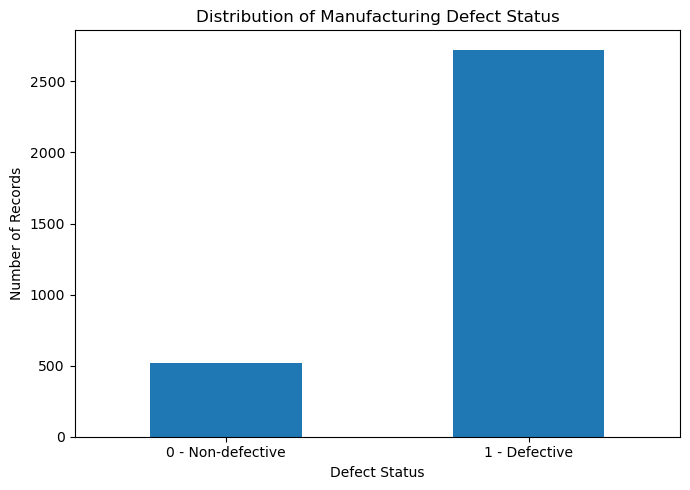

In [4]:
# Explore target variable distribution

TARGET_COLUMN = "DefectStatus"

# Count records in each class
target_counts = df[TARGET_COLUMN].value_counts().sort_index()

print("Target Class Distribution:")
print(target_counts)

# Calculate percentages
target_percentages = (
    df[TARGET_COLUMN]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nTarget Class Distribution (%):")
print(target_percentages.round(2))

# Visualise target distribution
plt.figure(figsize=(7, 5))

target_counts.plot(kind="bar", rot=0)

plt.title("Distribution of Manufacturing Defect Status")
plt.xlabel("Defect Status")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["0 - Non-defective", "1 - Defective"])
plt.tight_layout()
plt.show()

### 4.1 Observations from Target Distribution

The target variable `DefectStatus` contains two classes:

- Class 0 (Non-defective): 517 records (15.96%).
- Class 1 (Defective): 2,723 records (84.04%).

The distribution indicates a significant class imbalance, with defective records representing the majority class.

This imbalance may influence the performance of classification algorithms. A model may achieve high accuracy by favouring the majority class while performing poorly on the minority class.

Therefore, model performance will be evaluated using Accuracy, AUC, Precision, Recall, F1-score and Matthews Correlation Coefficient (MCC). Stratified train-test splitting will also be used to preserve the class distribution in both datasets.

## 5. Explore feature patterns

The following summaries compare average feature values and correlations with the target. These are exploratory descriptions, not proof of causation. In particular, features such as `DefectRate` and `QualityScore` should be checked to confirm that they would be available at the time a real prediction is made.

In [5]:
# Compare average numeric feature values for each target class
class_means = (
    df.groupby(TARGET_COLUMN)
    .mean(numeric_only=True)
    .T
)

# Calculate absolute difference between class means
if 0 in class_means.columns and 1 in class_means.columns:
    class_means["AbsoluteDifference"] = (
        class_means[0] - class_means[1]
    ).abs()

print("Feature averages by defect status:")
display(
    class_means.sort_values(
        "AbsoluteDifference",
        ascending=False
    ).round(3)
)

# Calculate correlation of features with target
correlations = (
    df.corr(numeric_only=True)[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
    .sort_values(key=abs, ascending=False)
)

print("\nFeature correlation with DefectStatus:")
display(correlations.to_frame().round(3))

Feature averages by defect status:


DefectStatus,0,1,AbsoluteDifference
ProductionCost,12158.877,12473.169,314.292
ProductionVolume,470.867,563.267,92.401
EnergyConsumption,2975.158,2991.027,15.868
QualityScore,85.442,79.126,6.316
MaintenanceHours,6.791,12.366,5.575
DefectRate,2.010,2.889,0.879
SupplierQuality,89.329,89.929,0.600
AdditiveMaterialCost,299.770,299.467,0.303
SafetyIncidents,4.698,4.571,0.127
WorkerProductivity,90.109,90.027,0.082



Feature correlation with DefectStatus:


,DefectStatus
MaintenanceHours,0.297
DefectRate,0.246
QualityScore,-0.199
ProductionVolume,0.129
StockoutRate,0.041
SupplierQuality,0.038
EnergyEfficiency,-0.035
ProductionCost,0.027
SafetyIncidents,-0.016
InventoryTurnover,0.007


In [6]:
# Inspect selected features across target classes

selected_features = [
    feature for feature in [
        "DefectRate",
        "QualityScore",
        "MaintenanceHours"
    ]
    if feature in df.columns
]

for feature in selected_features:

    print(f"\n{feature} by {TARGET_COLUMN}:")

    display(
        df.groupby(TARGET_COLUMN)[feature]
        .agg(["min", "median", "max", "mean", "std"])
        .round(3)
    )


DefectRate by DefectStatus:


,min,median,max,mean,std
DefectStatus,,,,,
0,0.511,1.978,4.968,2.010,1.003
1,0.501,3.027,4.999,2.889,1.315



QualityScore by DefectStatus:


,min,median,max,mean,std
DefectStatus,,,,,
0,60.302,85.864,99.997,85.442,9.238
1,60.010,78.575,99.992,79.126,11.743



MaintenanceHours by DefectStatus:


,min,median,max,mean,std
DefectStatus,,,,,
0,0,6.0,23,6.791,5.096
1,0,13.0,23,12.366,6.806


### 5.1 Observations from Feature Analysis

The comparison of feature averages and correlations across the two target classes reveals several patterns.

1. **MaintenanceHours:** This feature has the strongest positive correlation with DefectStatus (0.297). The average maintenance hours are higher for defective records (12.366) compared with non-defective records (6.791).

2. **DefectRate:** A positive correlation of 0.246 is observed. The average defect rate is 2.889 for defective records compared with 2.010 for non-defective records.

3. **QualityScore:** This feature has a negative correlation of -0.199. Non-defective records have a higher average quality score (85.442) than defective records (79.126).

4. **ProductionVolume:** Defective records show a higher average production volume (563.267) compared with non-defective records (470.867).

The analysis indicates that MaintenanceHours, DefectRate, QualityScore and ProductionVolume show relatively noticeable differences between the target classes.

However, correlation does not establish causation, and the observed relationships alone do not determine feature importance. The availability of each feature at the actual prediction time should also be considered to avoid potential data leakage.

These observations provide an initial understanding of the dataset and will help interpret the classification model results.

## 6. Prepare features and split the data

`X` contains the input features, while `y` contains the target labels. A stratified 80:20 split reserves 20% of the records for final evaluation and preserves the class proportions in both sets. The test set is not used to fit the models.

Scaling is applied inside pipelines for Logistic Regression, KNN, and SVM. This ensures the scaler is fitted only on training data and then applied to the test data, helping prevent data leakage from preprocessing.

In [7]:
# ============================================================
# 6. PREPARE FEATURES AND SPLIT THE DATA
# ============================================================

# Define configuration variables
TARGET_COLUMN = "DefectStatus"
RANDOM_STATE = 42

# Step 1: Separate input features (X) and target variable (y)

X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

print("Target classes:", sorted(y.unique()))

# Step 2: Perform stratified 80:20 train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Step 3: Display dataset dimensions

print("\nDataset split completed successfully!")

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

# Step 4: Display training class distribution

print("\nTraining class distribution:")

display(
    y_train.value_counts()
    .sort_index()
    .to_frame("Count")
)

print("\nTraining class proportions:")

display(
    y_train.value_counts(normalize=True)
    .sort_index()
    .round(4)
    .to_frame("Proportion")
)

# Step 5: Display testing class distribution

print("\nTesting class distribution:")

display(
    y_test.value_counts()
    .sort_index()
    .to_frame("Count")
)

print("\nTesting class proportions:")

display(
    y_test.value_counts(normalize=True)
    .sort_index()
    .round(4)
    .to_frame("Proportion")
)

# Step 6: Validate the split

assert len(X_train) + len(X_test) == len(df)
assert X_train.shape[1] == X_test.shape[1]
assert X_train.index.intersection(X_test.index).empty

print("\nValidation passed!")
print("Training and testing datasets are ready.")

Target classes: [np.int64(0), np.int64(1)]

Dataset split completed successfully!

Training feature shape: (2592, 16)
Testing feature shape: (648, 16)

Training target shape: (2592,)
Testing target shape: (648,)

Training class distribution:


,Count
DefectStatus,
0,414
1,2178



Training class proportions:


,Proportion
DefectStatus,
0,0.1597
1,0.8403



Testing class distribution:


,Count
DefectStatus,
0,103
1,545



Testing class proportions:


,Proportion
DefectStatus,
0,0.159
1,0.841



Validation passed!
Training and testing datasets are ready.


## 7. Define a common evaluation function

Using one function for all models keeps the metric calculations consistent. Precision, Recall, and F1 Score use class 1 as the positive class. AUC is calculated from the predicted probability for class 1 rather than the hard class prediction. MCC provides a single measure that accounts for all four confusion-matrix outcomes.

In [8]:
# ============================================================
# 7. DEFINE A COMMON EVALUATION FUNCTION
# ============================================================

def evaluate_model(model_name, fitted_model, X_eval, y_eval):
    """
    Calculate six classification performance metrics
    for a fitted machine learning model.
    """

    # Generate class predictions
    predictions = fitted_model.predict(X_eval)

    # Generate predicted probabilities for positive class (1)
    probabilities = fitted_model.predict_proba(X_eval)[:, 1]

    # Calculate evaluation metrics
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "AUC": roc_auc_score(y_eval, probabilities),
        "Precision": precision_score(
            y_eval, predictions, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, predictions, pos_label=1, zero_division=0
        ),
        "F1 Score": f1_score(
            y_eval, predictions, pos_label=1, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_eval, predictions)
    }

print("Common evaluation function defined successfully.")

Common evaluation function defined successfully.


## 8. Train the five classification models

All models use the same training and test partitions. The parameters below are the configurations used in this experiment. Scaling is included for Logistic Regression, KNN, and SVM because these algorithms can be sensitive to differences in feature scales. Decision Tree and Gaussian Naive Bayes are trained without a scaler here.

In [9]:
# Logistic Regression: standardise features within a pipeline.
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
logistic_model.fit(X_train, y_train)

# Decision Tree: limit depth and minimum leaf size to constrain complexity.
tree_model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
tree_model.fit(X_train, y_train)

# KNN: standardise features because distance calculations depend on scale.
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5)),
])
knn_model.fit(X_train, y_train)

# Gaussian Naive Bayes: probabilistic classifier using class-conditional
# Gaussian feature distributions.
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# SVM: use an RBF kernel; probability=True enables probability-based AUC.
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])
svm_model.fit(X_train, y_train)

print("All five models have been trained on the training split.")

All five models have been trained on the training split.


## 9. Evaluate and compare model performance

The next cell evaluates each fitted model on the same held-out test set. Scores are rounded for display only; the underlying values retain their precision.

In [10]:
# Keep a consistent name-to-model mapping for evaluation and saving.
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": nb_model,
    "Support Vector Machine": svm_model,
}

# Calculate all six required metrics for each model.
results = [
    evaluate_model(name, model, X_test, y_test)
    for name, model in models.items()
]

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8765,0.7960,0.8921,0.9706,0.9297,0.4582
Decision Tree,0.8843,0.8617,0.9468,0.9138,0.9300,0.6004
KNN,0.8673,0.7464,0.8857,0.9670,0.9246,0.4093
Gaussian Naive Bayes,0.8951,0.8268,0.9008,0.9835,0.9404,0.5479
Support Vector Machine,0.8256,0.8157,0.9408,0.8459,0.8908,0.4805


### 9.1 Model Performance Comparison and Observations

All five classification algorithms were evaluated using the same held-out test dataset and six performance metrics.

The following observations were obtained:

1. **Logistic Regression:** Achieved an accuracy of 87.65% and recall of 97.06%. It demonstrates strong identification of the positive class but has a comparatively lower MCC of 0.4582.

2. **Decision Tree:** Achieved the highest AUC (0.8617), precision (0.9468) and MCC (0.6004). These results indicate comparatively strong classification performance across the evaluated metrics.

3. **K-Nearest Neighbours:** Achieved an accuracy of 86.73% and recall of 96.70%. However, its AUC (0.7464) and MCC (0.4093) are the lowest among the five models.

4. **Gaussian Naive Bayes:** Achieved the highest accuracy (89.51%), recall (98.35%) and F1 score (94.04%). It performed particularly well in identifying positive-class records.

5. **Support Vector Machine:** Achieved an accuracy of 82.56% and precision of 94.08%. However, its recall (84.59%) was lower than that of the other four classifiers.

Overall, Gaussian Naive Bayes achieved the highest accuracy, recall and F1 score, while Decision Tree achieved the highest AUC, precision and MCC.

Considering the imbalanced target distribution, MCC and AUC provide additional insight into model performance beyond accuracy. Decision Tree is therefore considered a promising balanced candidate, subject to further examination of its confusion matrix and minority-class performance.

## 10. Confusion matrices and classification reports

A confusion matrix shows the counts of correct and incorrect predictions for each class. The classification report adds class-specific precision, recall, and F1 Score, which are especially useful when target classes are imbalanced.

In [11]:
# ============================================================
# 10. CONFUSION MATRICES AND CLASSIFICATION REPORTS
# ============================================================

for name, model in models.items():

    # Generate predictions
    predictions = model.predict(X_test)

    print(f"\n{'=' * 65}")
    print(f"MODEL: {name}")
    print("=" * 65)

    # 1. Display confusion matrix as a table
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    cm_df = pd.DataFrame(
        cm,
        index=[
            "Actual: Non-defective (0)",
            "Actual: Defective (1)"
        ],
        columns=[
            "Predicted: Non-defective (0)",
            "Predicted: Defective (1)"
        ]
    )

    print("\nConfusion Matrix:")
    display(cm_df)

    # 2. Display classification report as a table
    report = classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=[
            "Non-defective (0)",
            "Defective (1)"
        ],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    print("\nClassification Report:")
    display(report_df.round(4))


MODEL: Logistic Regression

Confusion Matrix:


,Predicted: Non-defective (0),Predicted: Defective (1)
Actual: Non-defective (0),39,64
Actual: Defective (1),16,529



Classification Report:


,precision,recall,f1-score,support
Non-defective (0),0.7091,0.3786,0.4937,103.0000
Defective (1),0.8921,0.9706,0.9297,545.0000
accuracy,0.8765,0.8765,0.8765,0.8765
macro avg,0.8006,0.6746,0.7117,648.0000
weighted avg,0.8630,0.8765,0.8604,648.0000



MODEL: Decision Tree

Confusion Matrix:


...

,precision,recall,f1-score,support
Non-defective (0),0.8302,0.4272,0.5641,103.0000
Defective (1),0.9008,0.9835,0.9404,545.0000
accuracy,0.8951,0.8951,0.8951,0.8951
macro avg,0.8655,0.7053,0.7522,648.0000
weighted avg,0.8896,0.8951,0.8805,648.0000



MODEL: Support Vector Machine

Confusion Matrix:


,Predicted: Non-defective (0),Predicted: Defective (1)
Actual: Non-defective (0),74,29
Actual: Defective (1),84,461



Classification Report:


,precision,recall,f1-score,support
Non-defective (0),0.4684,0.7184,0.5670,103.0000
Defective (1),0.9408,0.8459,0.8908,545.0000
accuracy,0.8256,0.8256,0.8256,0.8256
macro avg,0.7046,0.7822,0.7289,648.0000
weighted avg,0.8657,0.8256,0.8394,648.0000


## 10.1 Interpretation of Confusion Matrices and Classification Reports

The confusion matrices and classification reports provide a detailed evaluation of the five classification models across both target classes.

### Key Observations

| Model | Key Strength | Key Limitation |
|---|---|---|
| Logistic Regression | High recall for defective products (0.97) | Low recall for non-defective products (0.38) |
| Decision Tree | Balanced performance, with class 0 recall of 0.73 | Lower class 0 precision (0.61) |
| KNN | High recall for defective products (0.97) | Lowest class 0 recall (0.34) |
| Gaussian Naive Bayes | Highest class 1 recall (0.98) and F1-score (0.94) | Class 0 recall is relatively low (0.43) |
| Support Vector Machine | Good class 0 recall (0.72) | Lower class 1 recall (0.85) |

### Overall Assessment

The results indicate that Gaussian Naive Bayes performs particularly well in identifying defective products, while Decision Tree provides a more balanced performance across both classes.

Decision Tree achieves the highest MCC (0.6004), AUC (0.8617) and macro F1-score (0.80). It also identifies a larger proportion of non-defective records than the other classifiers.

Considering the class imbalance and the performance across both target classes, Decision Tree is selected as the strongest balanced candidate for this experiment. Gaussian Naive Bayes remains an alternative when identifying defective products is the primary objective.

The final selection should consider the operational impact of false-positive and false-negative predictions.

## 11. Feature Sensitivity Analysis: Impact of Excluding Quality-Related Features

This experiment evaluates the impact of excluding two quality-related features, `DefectRate` and `QualityScore`, on the performance of the five classification models.

The objective is to understand how model performance changes when these features are unavailable as input variables.

The experiment uses the same classification algorithms and evaluation metrics as the primary modelling exercise. A separate stratified train-test split is created, and the original trained models are retained without modification.

**Interpretation caution:** A change in model performance does not, by itself, establish data leakage. The feature definitions, measurement process and availability at prediction time must be examined before drawing conclusions.

In [12]:
# Features excluded for sensitivity analysis
excluded_features = ["DefectRate", "QualityScore"]

# Create reduced feature dataset
X_reduced = X.drop(columns=excluded_features)

# Recreate reduced training and testing datasets
X_train_reduced = X_reduced.loc[X_train.index]
X_test_reduced = X_reduced.loc[X_test.index]

# Preserve original target split
y_train_reduced = y_train.copy()
y_test_reduced = y_test.copy()

print("Reduced dataset:", X_reduced.shape)
print("Training features:", X_train_reduced.shape)
print("Testing features:", X_test_reduced.shape)
print("Training target:", y_train_reduced.shape)
print("Testing target:", y_test_reduced.shape)

Reduced dataset: (3240, 14)
Training features: (2592, 14)
Testing features: (648, 14)
Training target: (2592,)
Testing target: (648,)


### 11.1 Exclude Quality-Related Features

The two selected features, `DefectRate` and `QualityScore`, are excluded from the original input feature set.

A reduced dataset is created using the remaining 14 features. The target variable, `DefectStatus`, is retained without modification.

In [13]:
# ============================================================
# 11.1 EXCLUDE QUALITY-RELATED FEATURES
# ============================================================

# Identify features to be excluded
excluded_features = [
    "DefectRate",
    "QualityScore"
]

# Verify that both features exist
missing_features = [
    feature for feature in excluded_features
    if feature not in X.columns
]

if missing_features:
    raise ValueError(
        f"Features not found: {missing_features}"
    )

# Create reduced feature dataset
X_reduced = X.drop(columns=excluded_features)

# Retain original target variable
y_reduced = y.copy()

# Display feature information
print("FEATURE SENSITIVITY ANALYSIS")
print("=" * 45)

print("\nExcluded features:", excluded_features)
print("Original feature count:", X.shape[1])
print("Reduced feature count:", X_reduced.shape[1])

print("\nReduced feature matrix shape:", X_reduced.shape)
print("Target vector shape:", y_reduced.shape)

FEATURE SENSITIVITY ANALYSIS

Excluded features: ['DefectRate', 'QualityScore']
Original feature count: 16
Reduced feature count: 14

Reduced feature matrix shape: (3240, 14)
Target vector shape: (3240,)


### 11.2 Prepare Reduced Training and Testing Data

The reduced feature dataset is divided into training and testing sets using an 80:20 stratified split.

The same random state and stratification approach used in the primary experiment are maintained. This ensures that the same observations are used for training and testing, allowing a more consistent comparison between the original and reduced-feature experiments.

In [14]:
# ============================================================
# 11.2 PREPARE REDUCED TRAINING AND TESTING DATA
# ============================================================

X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = (
    train_test_split(
        X_reduced,
        y_reduced,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y_reduced
    )
)

# Display dataset dimensions
print("Reduced training feature shape:", X_train_reduced.shape)
print("Reduced testing feature shape:", X_test_reduced.shape)

print("\nReduced training target shape:", y_train_reduced.shape)
print("Reduced testing target shape:", y_test_reduced.shape)

# Verify that the same records are used as in the primary experiment
assert X_train_reduced.index.equals(X_train.index)
assert X_test_reduced.index.equals(X_test.index)

print("\nValidation successful!")
print("The original and reduced experiments use the same train-test records.")

Reduced training feature shape: (2592, 14)
Reduced testing feature shape: (648, 14)

Reduced training target shape: (2592,)
Reduced testing target shape: (648,)

Validation successful!
The original and reduced experiments use the same train-test records.


In [15]:
# Remove the two selected features
excluded_features = ["DefectRate", "QualityScore"]

X_reduced = X.drop(columns=excluded_features)

# Create reduced training and testing datasets
X_train_reduced = X_reduced.loc[X_train.index]
X_test_reduced = X_reduced.loc[X_test.index]

y_train_reduced = y_train.copy()
y_test_reduced = y_test.copy()

# Verify the datasets
print("Reduced feature dataset:", X_reduced.shape)
print("Training features:", X_train_reduced.shape)
print("Testing features:", X_test_reduced.shape)
print("Training target:", y_train_reduced.shape)
print("Testing target:", y_test_reduced.shape)

Reduced feature dataset: (3240, 14)
Training features: (2592, 14)
Testing features: (648, 14)
Training target: (2592,)
Testing target: (648,)


### 11.3 Train Five Models Using Reduced Features

The five classification algorithms are retrained using the reduced feature dataset.

The same model configurations used in the primary experiment are retained. Separate model instances are created using the `clone` function to prevent modification of the original trained models.

The models are trained using the reduced training dataset and will subsequently be evaluated using the corresponding reduced testing dataset.

In [16]:
from sklearn.base import clone

# Create copies of the original five models
reduced_models = {
    name: clone(model)
    for name, model in models.items()
}

# Train models using reduced features
for name, model in reduced_models.items():
    model.fit(X_train_reduced, y_train_reduced)
    print(f"{name}: Trained successfully")

print("\nAll five reduced-feature models have been trained.")

Logistic Regression: Trained successfully
Decision Tree: Trained successfully
KNN: Trained successfully
Gaussian Naive Bayes: Trained successfully
Support Vector Machine: Trained successfully

All five reduced-feature models have been trained.


### 11.4 Evaluate Reduced-Feature Models

The five models trained using the reduced feature set are evaluated on the held-out test dataset.

The same six evaluation metrics used in the primary experiment are calculated: Accuracy, AUC, Precision, Recall, F1-score and MCC.

A common evaluation function is used to maintain consistency across both experiments.

In [17]:
# ============================================================
# 11.4 EVALUATE REDUCED-FEATURE MODELS
# ============================================================

# Calculate all six evaluation metrics
reduced_results = [
    evaluate_model(
        name,
        model,
        X_test_reduced,
        y_test_reduced
    )
    for name, model in reduced_models.items()
]

# Create results DataFrame
reduced_results_df = (
    pd.DataFrame(reduced_results)
    .set_index("Model")
)

# Display reduced-feature model results
print("REDUCED-FEATURE MODEL PERFORMANCE")
display(reduced_results_df.round(4))

REDUCED-FEATURE MODEL PERFORMANCE


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8364,0.7374,0.8424,0.9908,0.9106,0.0362
Decision Tree,0.7238,0.7348,0.9336,0.7229,0.8149,0.3461
KNN,0.8086,0.6364,0.8502,0.9376,0.8918,0.0900
Gaussian Naive Bayes,0.8395,0.7560,0.8408,0.9982,0.9128,-0.0171
Support Vector Machine,0.7222,0.7349,0.9176,0.7358,0.8167,0.3014


#### 11.4.1 Detailed Confusion Matrices and Classification Reports

In addition to the overall evaluation metrics, confusion matrices and classification reports are generated for each reduced-feature model.

These reports provide a class-wise view of precision, recall and F1-score, helping assess how effectively each model identifies defective and non-defective products.

In [18]:
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

for name, model in reduced_models.items():

    print(f"\n{'='*60}")
    print(f"MODEL: {name}")
    print(f"{'='*60}")

    # Generate predictions
    predictions = model.predict(X_test_reduced)

    # Confusion matrix
    cm = confusion_matrix(
        y_test_reduced,
        predictions,
        labels=[0, 1]
    )

    cm_df = pd.DataFrame(
        cm,
        index=["Actual: Non-defective (0)", "Actual: Defective (1)"],
        columns=["Predicted: Non-defective (0)", "Predicted: Defective (1)"]
    )

    print("\nConfusion Matrix:")
    display(cm_df)

    # Classification report
    report = classification_report(
        y_test_reduced,
        predictions,
        labels=[0, 1],
        target_names=["Non-defective (0)", "Defective (1)"],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    print("\nClassification Report:")
    display(report_df.round(4))


MODEL: Logistic Regression

Confusion Matrix:


,Predicted: Non-defective (0),Predicted: Defective (1)
Actual: Non-defective (0),2,101
Actual: Defective (1),5,540



Classification Report:


,precision,recall,f1-score,support
Non-defective (0),0.2857,0.0194,0.0364,103.0000
Defective (1),0.8424,0.9908,0.9106,545.0000
accuracy,0.8364,0.8364,0.8364,0.8364
macro avg,0.5641,0.5051,0.4735,648.0000
weighted avg,0.7539,0.8364,0.7717,648.0000



MODEL: Decision Tree

Confusion Matrix:


...

,precision,recall,f1-score,support
Non-defective (0),0.0000,0.0000,0.0000,103.0000
Defective (1),0.8408,0.9982,0.9128,545.0000
accuracy,0.8395,0.8395,0.8395,0.8395
macro avg,0.4204,0.4991,0.4564,648.0000
weighted avg,0.7072,0.8395,0.7677,648.0000



MODEL: Support Vector Machine

Confusion Matrix:


,Predicted: Non-defective (0),Predicted: Defective (1)
Actual: Non-defective (0),67,36
Actual: Defective (1),144,401



Classification Report:


,precision,recall,f1-score,support
Non-defective (0),0.3175,0.6505,0.4268,103.0000
Defective (1),0.9176,0.7358,0.8167,545.0000
accuracy,0.7222,0.7222,0.7222,0.7222
macro avg,0.6176,0.6931,0.6217,648.0000
weighted avg,0.8222,0.7222,0.7547,648.0000


### 11.5 Compare Original and Reduced-Feature Results

The performance of the original models, trained using all 16 features, is compared with the performance of the reduced-feature models, trained using 14 features.

The comparison includes the difference in each evaluation metric.

A positive change indicates an improvement in the metric after excluding the two features, while a negative change indicates a reduction in performance.

This comparison helps assess the influence of `DefectRate` and `QualityScore` on the classification results. The same training and testing observations are used in both experiments to ensure a consistent comparison.

In [19]:
# ============================================================
# 11.5 COMPARE ORIGINAL AND REDUCED-FEATURE RESULTS
# ============================================================

metrics_to_compare = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

# Select the original and reduced results
original_metrics = results_df[metrics_to_compare]
reduced_metrics = reduced_results_df[metrics_to_compare]

# Calculate the change in performance
performance_comparison = pd.concat(
    {
        "Original (16 Features)": original_metrics,
        "Reduced (14 Features)": reduced_metrics,
        "Change": reduced_metrics - original_metrics
    },
    axis=1
)

print("ORIGINAL VS REDUCED-FEATURE MODEL PERFORMANCE")

display(performance_comparison.round(4))

ORIGINAL VS REDUCED-FEATURE MODEL PERFORMANCE


Original (16 Features)                            \
                                     Accuracy     AUC Precision  Recall   
Model                                                                     
Logistic Regression                    0.8765  0.7960    0.8921  0.9706   
Decision Tree                          0.8843  0.8617    0.9468  0.9138   
KNN                                    0.8673  0.7464    0.8857  0.9670   
Gaussian Naive Bayes                   0.8951  0.8268    0.9008  0.9835   
Support Vector Machine                 0.8256  0.8157    0.9408  0.8459   

                                        Reduced (14 Features)          \
                       F1 Score     MCC              Accuracy     AUC   
Model                                                                   
Logistic Regression      0.9297  0.4582                0.8364  0.7374   
Decision Tree            0.9300  0.6004                0.7238  0.7348   
KNN                      0.9246  0.4093                0.8086  0.6364   
Gaussian Naive Bayes     0.9404  0.5479                0.8395  0.7560   
Support Vector Machine   0.8908  0.4805                0.7222  0.7349   

                                                            Change          \
                       Precision  Recall F1 Score     MCC Accuracy     AUC   
Model                                                                        
Logistic Regression       0.8424  0.9908   0.9106  0.0362  -0.0401 -0.0586   
Decision Tree             0.9336  0.7229   0.8149  0.3461  -0.1605 -0.1268   
KNN                       0.8502  0.9376   0.8918  0.0900  -0.0586 -0.1101   
Gaussian Naive Bayes      0.8408  0.9982   0.9128 -0.0171  -0.0556 -0.0708   
Support Vector Machine    0.9176  0.7358   0.8167  0.3014  -0.1034 -0.0808   

                                                           
                       Precision  Recall F1 Score     MCC  
Model                                                      
Logistic Regression      -0.0496  0.0202  -0.0191 -0.4220  
Decision Tree            -0.0131 -0.1908  -0.1151 -0.2543  
KNN                      -0.0355 -0.0294  -0.0328 -0.3193  
Gaussian Naive Bayes     -0.0600  0.0147  -0.0276 -0.5650  
Support Vector Machine   -0.0232 -0.1101  -0.0741 -0.1791

### 11.6.1 Confusion Matrix and Classification Report Analysis

The confusion matrices and classification reports provide additional insights into the impact of excluding `DefectRate` and `QualityScore`.

The reduced-feature models demonstrate different classification behaviours:

- **Logistic Regression and Gaussian Naive Bayes** strongly favour predicting the defective class. While they achieve high recall for defective products, their ability to identify non-defective products is extremely poor.
- **KNN** also shows a preference for predicting defective products, resulting in low recall for non-defective products.
- **Decision Tree** provides the most balanced recall between the two classes, with 72.82% recall for non-defective products and 72.29% for defective products.
- **Support Vector Machine** also demonstrates a comparatively balanced classification pattern, although its overall accuracy is lower.

The results indicate that removing `DefectRate` and `QualityScore` reduces the models' ability to distinguish between defective and non-defective products. This suggests that these two features contain useful predictive information.

However, this experiment alone does not establish data leakage. Further investigation into how these features are measured and whether they are available at the actual prediction stage would be required.

Overall, the experiment highlights the importance of feature selection and the need to evaluate model performance across both classes, particularly when the target dataset is imbalanced.

## 12. Save Trained Models and Test Data

After evaluating the five classification models, the trained models are saved using Joblib for future use in the Streamlit application.

The original models, trained using all 16 input features, are saved separately. The held-out test dataset is also exported as a CSV file for testing and validation.

Saving the trained models allows the application to load and use the models without requiring retraining.

In [20]:
import os
import joblib

# Create model directory if it does not exist
model_dir = "model"
os.makedirs(model_dir, exist_ok=True)

# Save the five original trained models
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

for name, filename in model_files.items():
    joblib.dump(models[name], os.path.join(model_dir, filename))
    print(f"{name}: Saved successfully")

print("\nAll five original models have been saved.")

Logistic Regression: Saved successfully
Decision Tree: Saved successfully
KNN: Saved successfully
Gaussian Naive Bayes: Saved successfully
Support Vector Machine: Saved successfully

All five original models have been saved.


In [21]:
# Combine the original test features and target
test_data = X_test.copy()
test_data["DefectStatus"] = y_test

# Save the test dataset
test_data.to_csv("test_data.csv", index=False)

# Verify the saved dataset
print("Test dataset saved successfully.")
print("Dataset shape:", test_data.shape)
print("Target column:", "DefectStatus")

Test dataset saved successfully.
Dataset shape: (648, 17)
Target column: DefectStatus


In [22]:
import os

print("FINAL ARTIFACT VERIFICATION")
print("=" * 40)

# Verify model files
for filename in model_files.values():
    path = os.path.join(model_dir, filename)
    print(f"{filename}: {'Found' if os.path.exists(path) else 'Missing'}")

# Verify test dataset
print(
    "test_data.csv:",
    "Found" if os.path.exists("test_data.csv") else "Missing"
)

FINAL ARTIFACT VERIFICATION
logistic_regression.joblib: Found
decision_tree.joblib: Found
knn.joblib: Found
naive_bayes.joblib: Found
svm.joblib: Found
test_data.csv: Found


## 13. Conclusion

In this assignment, five supervised machine learning classification algorithms were implemented to predict manufacturing defects: Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes and Support Vector Machine.

The models were trained and evaluated using a stratified 80:20 train-test split. Their performance was compared using Accuracy, AUC, Precision, Recall, F1-score and Matthews Correlation Coefficient (MCC).

The evaluation highlighted differences in model performance, particularly in identifying defective and non-defective products in an imbalanced dataset. The Decision Tree demonstrated a comparatively balanced performance, while Gaussian Naive Bayes achieved the highest accuracy and recall for the defective class in the original experiment.

A feature sensitivity experiment was also conducted by excluding `DefectRate` and `QualityScore`. The results demonstrated the impact of these features on classification performance and highlighted the importance of evaluating both classes rather than relying on accuracy alone.

Finally, all five original trained models and the held-out test dataset were saved for integration with the Streamlit application.

This assignment provided practical experience in data exploration, preprocessing, classification, model evaluation, feature sensitivity analysis and model deployment preparation.